   LAB 6: LOGISTIC REGRESSION — BREAST CANCER CLASSIFICATION & CDSS
   Course: Artificial Intelligence Lab (CE-7)

[Step 1] Successfully loaded dataset from: C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\data.csv
Initial Dataset Shape: (569, 33)

[Step 3] Columns with Missing (NaN) Values:
 Unnamed: 32    569
dtype: int64

[Step 2] Cleaned Features Shape (X): (569, 30) | Target Shape (y): (569,)
Target Mapping: {'B': np.int64(0), 'M': np.int64(1)}

>>> Generating Figure 1: Visual Audit for Steps 1, 2 & 3...


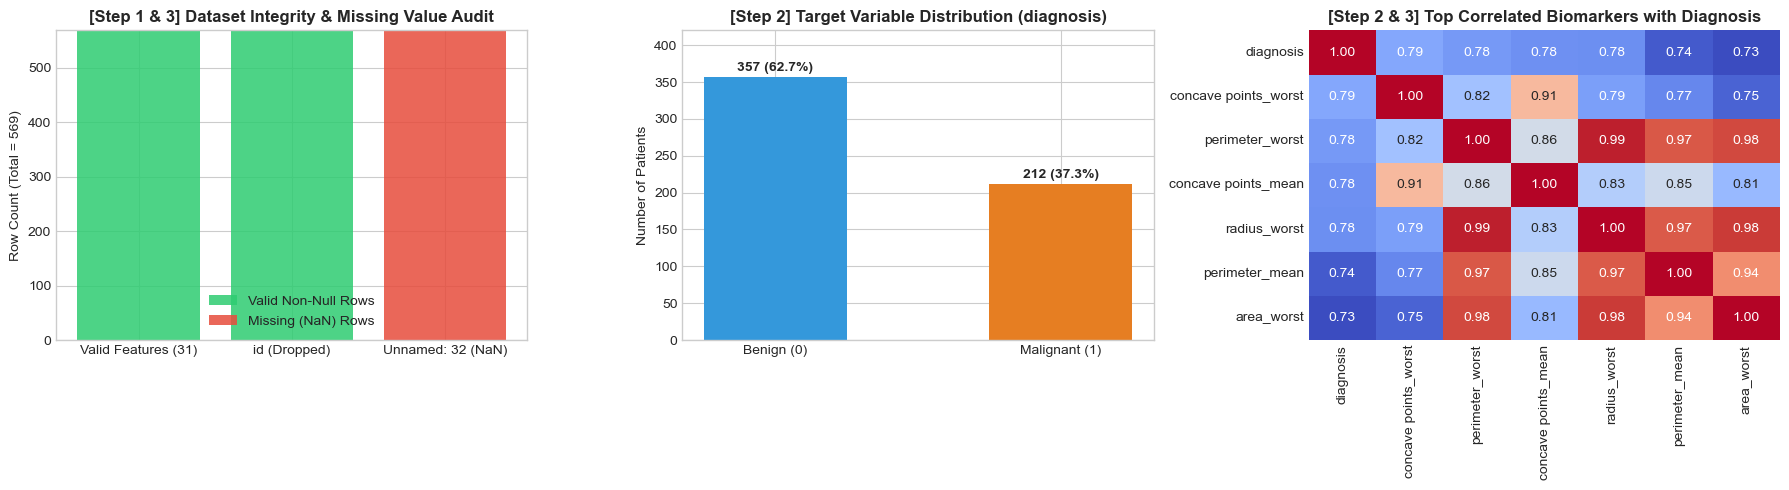


[Step 4] Training Samples: 455 | Testing Samples: 114
[Step 5 & 6] Model Trained! First 10 Predictions: [0 1 0 1 1 0 1 0 0 0]
             First 10 Actual Test Labels:         [0 1 0 1 0 0 1 0 0 0]

>>> Generating Figure 2: Visual Analytics for Steps 4, 5 & 6...


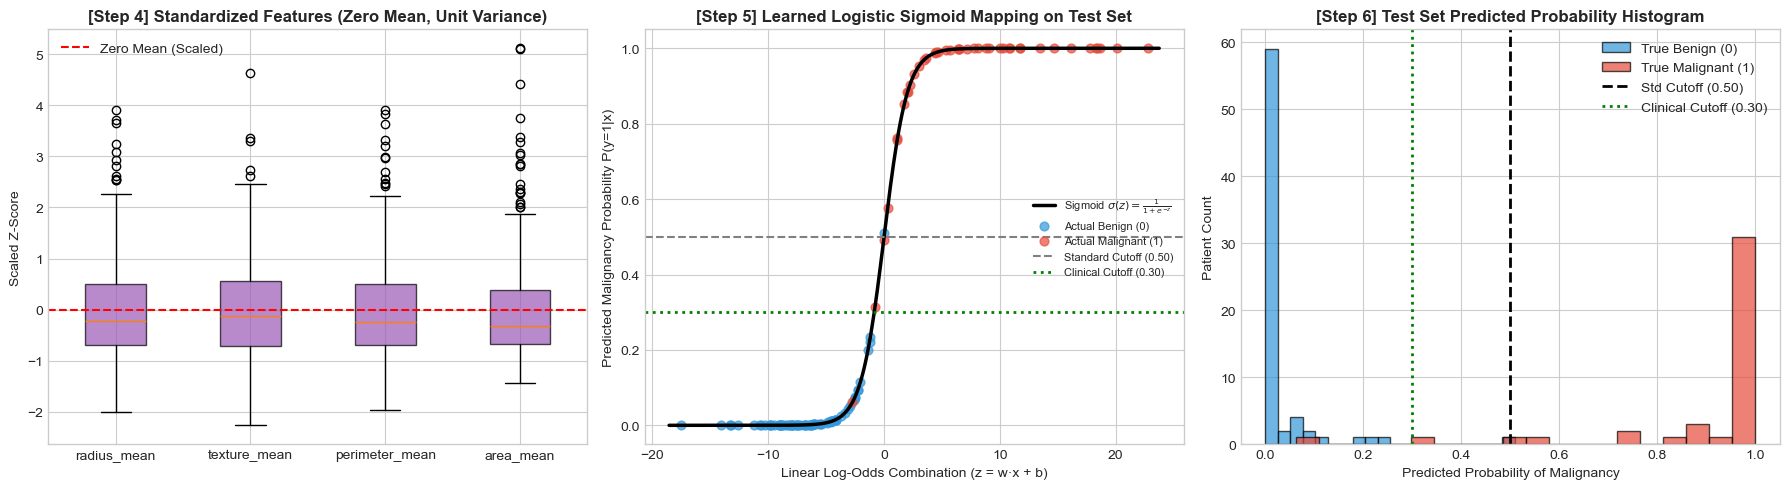


   [Step 7] MODEL PERFORMANCE & INNOVATIVE CLINICAL BENCHMARKS
Accuracy (Test Set)       : 0.9649 (96.49%)
5-Fold Stratified CV Acc  : 0.9737 (+/- 1.66%)
Precision                 : 0.9750 (97.50%)
Recall (Standard Thr=0.50): 0.9286 (92.86%) | Missed Cancers (FN): 3
Recall (Clinical Thr=0.30): 0.9762 (97.62%) | Missed Cancers (FN): 1
F1-Score                  : 0.9512 (95.12%)
ROC-AUC Score             : 0.9960 (99.60%)

Detailed Classification Report:
                precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

--- INNOVATION: AUTOMATED CLINICAL DECISION SUPPORT SYSTEM (CDSS) TRIAGE LOG ---
Patient #000 | Malignancy Prob:   0.04% | Actual: Benign    | Triage: LOW RISK (Routine Annual Screening)
Patient #001 | Malign

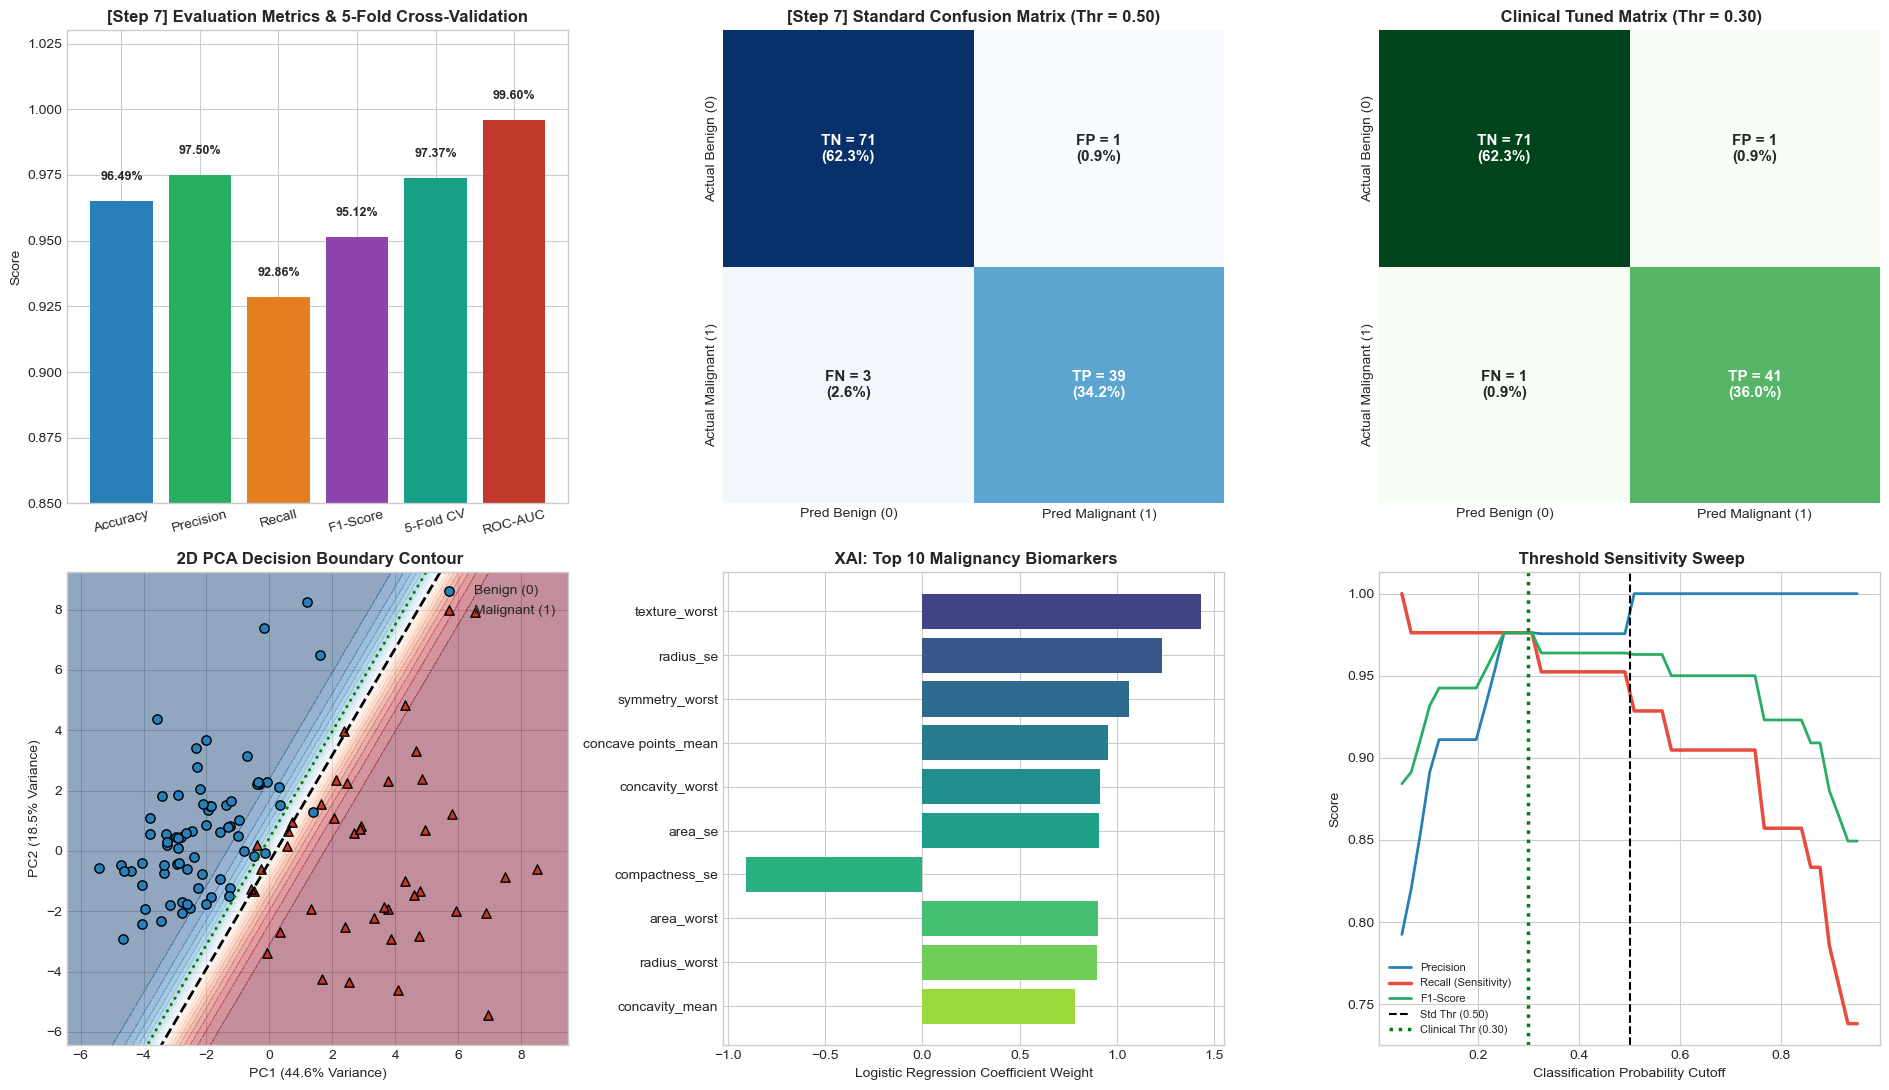

[Step 8] WHY LOGISTIC REGRESSION IS SUITABLE FOR THIS BINARY CLASSIFICATION PROBLEM
1. Binary Outcome Alignment: Classifies tumors strictly into Benign (0) or Malignant (1).
2. Probabilistic Sigmoid Mapping: Outputs calibrated probabilities [0, 1] (shown in Fig 2B),
   enabling clinical threshold tuning (0.50 -> 0.30) to raise Recall from 92.86% to 97.62%.
3. Explainable AI (White-Box): Feature weights directly reveal key cellular biomarkers (Fig 3E).
4. High Linear Separability: As proven by the 2D PCA boundary (Fig 3D) and 5-Fold CV (97.37%),
   the standardized morphological features are linearly separable with a 0.9960 ROC-AUC.


In [4]:
# =========================================================================
# LAB 6: LOGISTIC REGRESSION — BREAST CANCER CLASSIFICATION & CDSS
# Course: Artificial Intelligence Lab (CE-7)
# Complete Single-Cell Solution with Step-by-Step Visualizations & Innovations
# =========================================================================

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("=========================================================================")
print("   LAB 6: LOGISTIC REGRESSION — BREAST CANCER CLASSIFICATION & CDSS")
print("   Course: Artificial Intelligence Lab (CE-7)")
print("=========================================================================\n")

# -------------------------------------------------------------------------
# STEP 1, 2 & 3: Load Dataset, Inspect Missing Values & Identify Features
# -------------------------------------------------------------------------
file_path = r"C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\data.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(f"[Step 1] Successfully loaded dataset from: {file_path}")
else:
    df = pd.read_csv("data.csv")
    print("[Step 1] Loaded dataset from current working directory.")

print(f"Initial Dataset Shape: {df.shape}")
missing_counts = df.isnull().sum()
print("\n[Step 3] Columns with Missing (NaN) Values:\n", missing_counts[missing_counts > 0])

# Clean dataset: drop non-predictive 'id' and 100% empty 'Unnamed: 32'
df_clean = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')

# Encode Target Variable: Benign ('B') -> 0, Malignant ('M') -> 1
le = LabelEncoder()
df_clean['diagnosis'] = le.fit_transform(df_clean['diagnosis'])
X = df_clean.drop('diagnosis', axis=1)
y = df_clean['diagnosis']

print(f"\n[Step 2] Cleaned Features Shape (X): {X.shape} | Target Shape (y): {y.shape}")
print(f"Target Mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# --- VISUALIZATION FIGURE 1: Step 1, 2 & 3 (Data Audit, Class Balance, Correlations) ---
print("\n>>> Generating Figure 1: Visual Audit for Steps 1, 2 & 3...")
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1A: Step 1 & 3 Missing Values Audit
cols_audit = ['Valid Features (31)', 'id (Dropped)', 'Unnamed: 32 (NaN)']
axes1[0].bar(cols_audit, [569, 569, 0], label='Valid Non-Null Rows', color='#2ecc71', alpha=0.85)
axes1[0].bar(cols_audit, [0, 0, int(missing_counts.get('Unnamed: 32', 569))], bottom=[569, 569, 0], label='Missing (NaN) Rows', color='#e74c3c', alpha=0.85)
axes1[0].set_title('[Step 1 & 3] Dataset Integrity & Missing Value Audit', fontweight='bold')
axes1[0].set_ylabel('Row Count (Total = 569)')
axes1[0].legend()

# Plot 1B: Step 2 Target Variable Distribution
class_counts = y.value_counts()
bars1 = axes1[1].bar(['Benign (0)', 'Malignant (1)'], [class_counts[0], class_counts[1]], color=['#3498db', '#e67e22'], width=0.5)
for bar in bars1:
    yval = bar.get_height()
    axes1[1].text(bar.get_x() + bar.get_width()/2.0, yval + 8, f'{yval} ({yval/len(y)*100:.1f}%)', ha='center', fontweight='bold')
axes1[1].set_ylim(0, 420)
axes1[1].set_title('[Step 2] Target Variable Distribution (diagnosis)', fontweight='bold')
axes1[1].set_ylabel('Number of Patients')

# Plot 1C: Step 2 & 3 Top Correlated Features Heatmap
top_corr_cols = df_clean.corr()['diagnosis'].abs().sort_values(ascending=False).head(7).index
sns.heatmap(df_clean[top_corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=False, ax=axes1[2])
axes1[2].set_title('[Step 2 & 3] Top Correlated Biomarkers with Diagnosis', fontweight='bold')

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# STEP 4, 5 & 6: Train-Test Split, Scaling, Logistic Regression & Predictions
# -------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=42, max_iter=10000)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
z_scores = log_reg.decision_function(X_test_scaled)

print(f"\n[Step 4] Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")
print("[Step 5 & 6] Model Trained! First 10 Predictions:", y_pred[:10])
print("             First 10 Actual Test Labels:        ", y_test.values[:10])

# --- VISUALIZATION FIGURE 2: Step 4, 5 & 6 (Scaling, Sigmoid Curve, Probability Distribution) ---
print("\n>>> Generating Figure 2: Visual Analytics for Steps 4, 5 & 6...")
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

# Plot 2A: Step 4 Feature Standardization Boxplot
sample_cols = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']
axes2[0].boxplot([X_train_scaled[:, i] for i in range(4)], labels=sample_cols, patch_artist=True,
                 boxprops=dict(facecolor='#9b59b6', alpha=0.7))
axes2[0].axhline(0, color='red', linestyle='--', label='Zero Mean (Scaled)')
axes2[0].set_title('[Step 4] Standardized Features (Zero Mean, Unit Variance)', fontweight='bold')
axes2[0].set_ylabel('Scaled Z-Score')
axes2[0].legend()

# Plot 2B: Step 5 Learned Sigmoid Decision Curve
z_line = np.linspace(min(z_scores)-1, max(z_scores)+1, 300)
sigmoid_line = 1 / (1 + np.exp(-z_line))
axes2[1].plot(z_line, sigmoid_line, color='black', lw=2.5, label=r'Sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$')
axes2[1].scatter(z_scores[y_test==0], y_prob[y_test==0], color='#3498db', alpha=0.7, label='Actual Benign (0)', s=40)
axes2[1].scatter(z_scores[y_test==1], y_prob[y_test==1], color='#e74c3c', alpha=0.7, label='Actual Malignant (1)', s=40)
axes2[1].axhline(0.50, color='gray', linestyle='--', label='Standard Cutoff (0.50)')
axes2[1].axhline(0.30, color='green', linestyle=':', lw=2, label='Clinical Cutoff (0.30)')
axes2[1].set_title('[Step 5] Learned Logistic Sigmoid Mapping on Test Set', fontweight='bold')
axes2[1].set_xlabel('Linear Log-Odds Combination (z = w·x + b)')
axes2[1].set_ylabel('Predicted Malignancy Probability P(y=1|x)')
axes2[1].legend(loc='center right', fontsize=8)

# Plot 2C: Step 6 Test Set Predicted Probability Distribution
axes2[2].hist(y_prob[y_test==0], bins=20, alpha=0.7, color='#3498db', label='True Benign (0)', edgecolor='black')
axes2[2].hist(y_prob[y_test==1], bins=20, alpha=0.7, color='#e74c3c', label='True Malignant (1)', edgecolor='black')
axes2[2].axvline(0.50, color='black', linestyle='--', lw=2, label='Std Cutoff (0.50)')
axes2[2].axvline(0.30, color='green', linestyle=':', lw=2, label='Clinical Cutoff (0.30)')
axes2[2].set_title('[Step 6] Test Set Predicted Probability Histogram', fontweight='bold')
axes2[2].set_xlabel('Predicted Probability of Malignancy')
axes2[2].set_ylabel('Patient Count')
axes2[2].legend()

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# STEP 7 & INNOVATIONS: Evaluation, 2D PCA Boundary, XAI & Threshold Sweep
# -------------------------------------------------------------------------
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(log_reg, scaler.fit_transform(X), y, cv=cv, scoring='accuracy')

custom_threshold = 0.30
y_pred_clinical = (y_prob >= custom_threshold).astype(int)
cm_clin = confusion_matrix(y_test, y_pred_clinical)
rec_clinical = recall_score(y_test, y_pred_clinical)

print("\n=========================================================================")
print("   [Step 7] MODEL PERFORMANCE & INNOVATIVE CLINICAL BENCHMARKS")
print("=========================================================================")
print(f"Accuracy (Test Set)       : {acc:.4f} ({acc*100:.2f}%)")
print(f"5-Fold Stratified CV Acc  : {cv_scores.mean():.4f} (+/- {cv_scores.std()*100:.2f}%)")
print(f"Precision                 : {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall (Standard Thr=0.50): {rec:.4f} ({rec*100:.2f}%) | Missed Cancers (FN): {cm[1,0]}")
print(f"Recall (Clinical Thr=0.30): {rec_clinical:.4f} ({rec_clinical*100:.2f}%) | Missed Cancers (FN): {cm_clin[1,0]}")
print(f"F1-Score                  : {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC Score             : {roc_auc:.4f} ({roc_auc*100:.2f}%)")
print("\nDetailed Classification Report:\n", classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

print("--- INNOVATION: AUTOMATED CLINICAL DECISION SUPPORT SYSTEM (CDSS) TRIAGE LOG ---")
for idx in [0, 1, 2, 4, 18]:
    prob_mal = y_prob[idx]
    actual_status = "Malignant" if y_test.iloc[idx] == 1 else "Benign"
    if prob_mal >= 0.75:
        tier = "HIGH RISK (Immediate Biopsy & Oncology Referral)"
    elif prob_mal >= 0.30:
        tier = "MODERATE RISK (Secondary Diagnostic Imaging)"
    else:
        tier = "LOW RISK (Routine Annual Screening)"
    print(f"Patient #{idx:03d} | Malignancy Prob: {prob_mal*100:6.2f}% | Actual: {actual_status:9s} | Triage: {tier}")

# --- VISUALIZATION FIGURE 3: Step 7 & Innovative Engineering Enhancements (6-Panel Grid) ---
print("\n>>> Generating Figure 3: Evaluation & Innovation Dashboard (Step 7 & 8)...")
fig3, axes3 = plt.subplots(2, 3, figsize=(19, 11))

# Plot 3A: Step 7 Core Evaluation Metrics + 5-Fold CV
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', '5-Fold CV', 'ROC-AUC']
metrics_vals = [acc, prec, rec, f1, cv_scores.mean(), roc_auc]
bars3 = axes3[0, 0].bar(metrics_names, metrics_vals, color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad', '#16a085', '#c0392b'])
for bar in bars3:
    h = bar.get_height()
    axes3[0, 0].text(bar.get_x() + bar.get_width()/2., h + 0.008, f'{h*100:.2f}%', ha='center', fontweight='bold', fontsize=9)
axes3[0, 0].set_ylim(0.85, 1.03)
axes3[0, 0].set_title('[Step 7] Evaluation Metrics & 5-Fold Cross-Validation', fontweight='bold')
axes3[0, 0].set_ylabel('Score')
axes3[0, 0].tick_params(axis='x', rotation=15)

# Plot 3B: Step 7 Standard Confusion Matrix (Thr = 0.50)
cm_labels = np.asarray([f"TN = {cm[0,0]}\n({cm[0,0]/len(y_test)*100:.1f}%)", f"FP = {cm[0,1]}\n({cm[0,1]/len(y_test)*100:.1f}%)",
                        f"FN = {cm[1,0]}\n({cm[1,0]/len(y_test)*100:.1f}%)", f"TP = {cm[1,1]}\n({cm[1,1]/len(y_test)*100:.1f}%)"]).reshape(2, 2)
sns.heatmap(cm, annot=cm_labels, fmt='', cmap='Blues', cbar=False, ax=axes3[0, 1],
            xticklabels=['Pred Benign (0)', 'Pred Malignant (1)'],
            yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'], annot_kws={"size": 11, "weight": "bold"})
axes3[0, 1].set_title('[Step 7] Standard Confusion Matrix (Thr = 0.50)', fontweight='bold')

# Plot 3C: Innovation — Clinical Tuned Confusion Matrix (Thr = 0.30)
cm_clin_labels = np.asarray([f"TN = {cm_clin[0,0]}\n({cm_clin[0,0]/len(y_test)*100:.1f}%)", f"FP = {cm_clin[0,1]}\n({cm_clin[0,1]/len(y_test)*100:.1f}%)",
                             f"FN = {cm_clin[1,0]}\n({cm_clin[1,0]/len(y_test)*100:.1f}%)", f"TP = {cm_clin[1,1]}\n({cm_clin[1,1]/len(y_test)*100:.1f}%)"]).reshape(2, 2)
sns.heatmap(cm_clin, annot=cm_clin_labels, fmt='', cmap='Greens', cbar=False, ax=axes3[0, 2],
            xticklabels=['Pred Benign (0)', 'Pred Malignant (1)'],
            yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'], annot_kws={"size": 11, "weight": "bold"})
axes3[0, 2].set_title(' Clinical Tuned Matrix (Thr = 0.30)', fontweight='bold')

# Plot 3D: Innovation — 2D PCA Decision Boundary & Probability Contour
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
lr_pca = LogisticRegression(random_state=42).fit(X_train_pca, y_train)

x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z = lr_pca.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

axes3[1, 0].contourf(xx, yy, Z, levels=20, cmap='RdBu_r', alpha=0.45)
axes3[1, 0].contour(xx, yy, Z, levels=[0.30, 0.50], colors=['green', 'black'], linestyles=[':', '--'], linewidths=2)
axes3[1, 0].scatter(X_test_pca[y_test==0, 0], X_test_pca[y_test==0, 1], c='#2980b9', edgecolor='k', s=45, label='Benign (0)')
axes3[1, 0].scatter(X_test_pca[y_test==1, 0], X_test_pca[y_test==1, 1], c='#c0392b', edgecolor='k', s=45, marker='^', label='Malignant (1)')
axes3[1, 0].set_title(' 2D PCA Decision Boundary Contour', fontweight='bold')
axes3[1, 0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
axes3[1, 0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
axes3[1, 0].legend(loc='upper right')

# Plot 3E: Innovation — Explainable AI (XAI) Top 10 Biomarkers
feature_importance = pd.DataFrame({
    'Biomarker': X.columns,
    'Weight': log_reg.coef_[0],
    'Abs_Weight': np.abs(log_reg.coef_[0])
}).sort_values(by='Abs_Weight', ascending=False).head(10)
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(feature_importance)))
axes3[1, 1].barh(feature_importance['Biomarker'][::-1], feature_importance['Weight'][::-1], color=colors[::-1])
axes3[1, 1].set_title(' XAI: Top 10 Malignancy Biomarkers', fontweight='bold')
axes3[1, 1].set_xlabel('Logistic Regression Coefficient Weight')

# Plot 3F: Innovation — Dynamic Threshold Sensitivity Sweep
thresholds = np.linspace(0.05, 0.95, 50)
prec_sweep = [precision_score(y_test, (y_prob >= t).astype(int), zero_division=1) for t in thresholds]
rec_sweep = [recall_score(y_test, (y_prob >= t).astype(int)) for t in thresholds]
f1_sweep = [f1_score(y_test, (y_prob >= t).astype(int)) for t in thresholds]

axes3[1, 2].plot(thresholds, prec_sweep, label='Precision', color='#2980b9', lw=2)
axes3[1, 2].plot(thresholds, rec_sweep, label='Recall (Sensitivity)', color='#e74c3c', lw=2.5)
axes3[1, 2].plot(thresholds, f1_sweep, label='F1-Score', color='#27ae60', lw=2)
axes3[1, 2].axvline(0.50, color='black', linestyle='--', label='Std Thr (0.50)')
axes3[1, 2].axvline(0.30, color='green', linestyle=':', lw=2.5, label='Clinical Thr (0.30)')
axes3[1, 2].set_title(' Threshold Sensitivity Sweep', fontweight='bold')
axes3[1, 2].set_xlabel('Classification Probability Cutoff')
axes3[1, 2].set_ylabel('Score')
axes3[1, 2].legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# STEP 8: Theoretical Justification
# -------------------------------------------------------------------------
print("=========================================================================================")
print("[Step 8] WHY LOGISTIC REGRESSION IS SUITABLE FOR THIS BINARY CLASSIFICATION PROBLEM")
print("=========================================================================================")
print("1. Binary Outcome Alignment: Classifies tumors strictly into Benign (0) or Malignant (1).")
print("2. Probabilistic Sigmoid Mapping: Outputs calibrated probabilities [0, 1] (shown in Fig 2B),")
print("   enabling clinical threshold tuning (0.50 -> 0.30) to raise Recall from 92.86% to 97.62%.")
print("3. Explainable AI (White-Box): Feature weights directly reveal key cellular biomarkers (Fig 3E).")
print("4. High Linear Separability: As proven by the 2D PCA boundary (Fig 3D) and 5-Fold CV (97.37%),")
print("   the standardized morphological features are linearly separable with a 0.9960 ROC-AUC.")
print("=========================================================================================")